In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import matplotlib
import scipy as sp
from sklearn.linear_model import LogisticRegression
import util

from scipy.stats import qmc
from numpy.random import Generator, PCG64
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from mpl_toolkits.basemap import Basemap
import matplotlib as mpl
import tqdm
from pathlib import Path
from scipy.signal import argrelextrema
import seaborn as sns

def stat_dist_theory_res(D,*data):
    A,q_c,q_r = data
    x_pos = np.dot(np.transpose(np.where(A>=0,A,0)),D)
    x_neg = np.dot(np.transpose(np.where(A<0,-A,0)),D)
    # out = np.zeros(len(D))
    # for i in range(len(D)):
    #     out[i] = D[i] - (1+x_pos[i])*q_c[i]/((1+x_pos)*q_c[i] + (1+x_neg)*q_r[i])
    out = D - (1+x_pos)*q_c/((1+x_pos)*q_c + (1+x_neg)*q_r)
    return out

In [2]:
%run DataProcessingTE.py
# Outputs the following:
    # df_AM22 - processed individual TE data from Armstrong McKay et al 2022
    # df_W24 - TE-TE interactions from Wunderling et al 2024
    # df_SSPs - global mean surface temp. anomalies vs pre-industrial (1850-1900). Historical and several SSPs
        # See scenarios for the list of scenarios 

# Loading pre-saved interaction matrices
A = [np.loadtxt("../Data/Simulations/TE/Interaction matrices/A_%s.csv"%r) for r in range(500)]

# (re)-calculating sigmoid betas with value at T_min of 0.001 (i.e. 0.1%)
betas = []
value_at_min=0.001
for x in df_AM22[['Threshold (°C) - Min.','Threshold (°C) - Est.','Threshold (°C) - Max.']].values:
    betas.append(float(sigmoid_beta(x[0],x[1],x[2],value_at_min=value_at_min)))
df_AM22['Sigmoid Beta'] = betas
Tmin = df_AM22.loc['ENSO']['Threshold (°C) - Min.']
Tmax = df_AM22.loc['ENSO']['Threshold (°C) - Max.']
df_AM22.loc['ENSO','Sigmoid Beta'] = np.log(1/value_at_min - 1)/(np.mean([Tmin,Tmax])-Tmin)
betas = df_AM22['Sigmoid Beta'].to_numpy() # important to turn into numpy array for computational speed!!

q_c = 1/(df_AM22['CollapseTime'].to_numpy()+1) # collapse leverage
T_lim = np.array(df_AM22['T_lim'].to_list()) # tipping thresholds
p_r = 1/(10*df_AM22['CollapseTime'].to_numpy()+1) # recovery probabilities: $\tau_{r,i} = 10\tau_{c,i}$

/home/jbara/Documents/Code/test-env/Notebooks/DataProcessingTE.py:21: RuntimeWarning: Mean of empty slice
  return np.exp(np.nanmean(np.log([minstr,maxstr])))


In [18]:
# Scenarios:
    # 1) Ramp up to 2C, stabilise for 200y @ 2C
        # 1a) Ramp down to 0
        # 1b) Stabilise for another 1ky
    # 2) Ramp up to 4C, stabilise for 200y @ 4C
        # 2a) Ramp down to 0
        # 2b) Stabilise for another 1ky
scenarios = ['1a','1b','2a','2b']
temps = {}
temps['1a'] = np.concatenate((np.arange(0,2.01,step=0.02),
                         np.ones(200)*2,
                         np.arange(0,2,step=0.02)[::-1]))
temps['1b'] = np.concatenate((np.arange(0,2.01,step=0.02),
                         np.ones(1200)*2))
# temps['1c'] = np.concatenate((np.arange(0,2.01,step=0.02),
#                          np.ones(1200)*2,
#                          np.arange(0,2,step=0.02)[::-1]))

temps['2a'] = np.concatenate((np.arange(0,4.01,step=0.02),
                         np.ones(200)*4,
                         np.arange(0,4,step=0.02)[::-1]))
temps['2b'] = np.concatenate((np.arange(0,4.01,step=0.02),
                         np.ones(1200)*4))

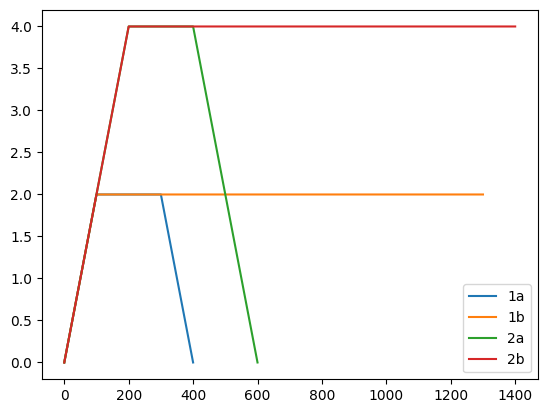

In [17]:
for s in ['1a','1b','2a','2b']:
    plt.plot(temps[s],label=s)
plt.legend()

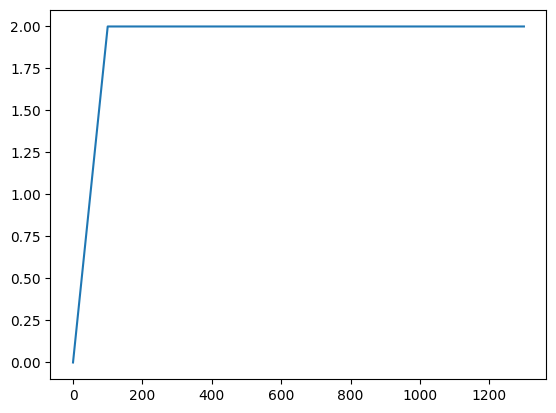

In [34]:
plt.plot(temps['1b'])

In [20]:
# years = np.arange(1850, 2350) 
len_sample=500
# T = len(years)
# GMST_hist = df_SSPs['Historical']['Mean'].to_numpy()

p_c = {s:np.ones((len(temps[s]), len(df_AM22)))/(df_AM22['CollapseTime'].to_numpy()+1) for s in scenarios}
# p_c *= 1/(df_AM22['CollapseTime'].to_numpy()+1)
# for t in range(len(GMST_hist)):
#     p_c[:,t,:] *= logistic(GMST_hist[t],T_lim,betas)
for s in scenarios:
    for t in range(1,len(temps[s])):
        p_c[s][t,:] *= logistic(temps[s][t], T_lim, betas)

In [25]:
D = {s:np.zeros((len_sample, len(TEs), len(temps[s]))) for s in scenarios}
for s in tqdm.tqdm(scenarios):
    for r in (range(len_sample)):
        for t in range(1, len(temps[s])):
            D[s][r,:,t] = util.environmental_update(D[s][r,:,t-1],A[r],p_c=p_c[s][t,:],p_r=p_r)

D_noint = {s:np.zeros((len(TEs), len(temps[s]))) for s in scenarios}
for s in tqdm.tqdm(scenarios):
    for t in (range(1,len(temps[s]))):
        D_noint[s][:,t] = util.environmental_update(D_noint[s][:,t-1],np.zeros((len(TEs),len(TEs))),p_c=p_c[s][t,:],p_r=p_r)

100%|█████████████████████████████████████████████| 4/4 [00:00<00:00, 34.87it/s]


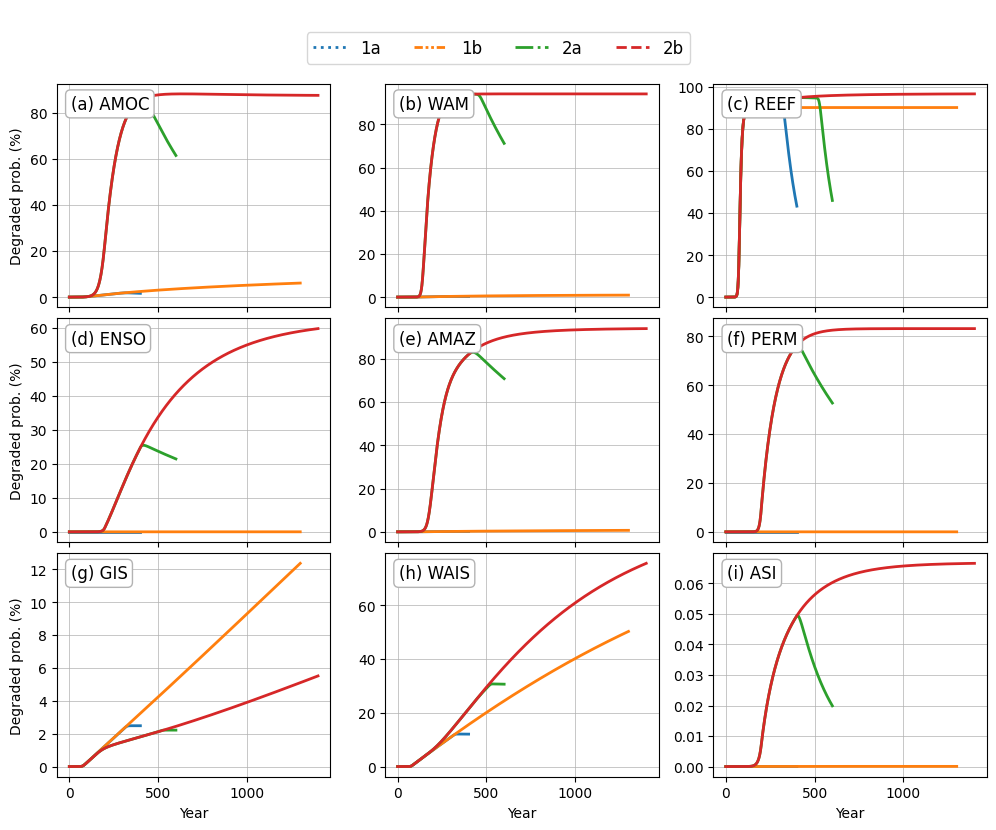

In [33]:
fig,axs = plt.subplots(figsize=(12,9),nrows=3,ncols=3,sharex=True,sharey=False)
fig.subplots_adjust(hspace=0.05) # hspace=0.05

prop_cycle = plt.rcParams['axes.prop_cycle']
colors = prop_cycle.by_key()['color']
linestyles = [':',(0, (3, 1, 1, 1, 1, 1)),'-.','--', (2,(10,3)) ,(5,(10,3))]
scen_labels = scenarios
# SSP_labs = ['1-1.9', '1-2.6', '2-4.5', '3-7.0', '5-8.5']

TE_ordered = ['AMOC', 'WAM', 'REEF',
              'ENSO', 'AMAZ','PERM',
              'GIS', 'WAIS', 'ASI']
letters = ['(%s)'%l for l in 'abcdefghi']
TE_ind = {te:i for i,te in enumerate(TEs)}
for i_ax,te in enumerate(TE_ordered):
    i = TE_ind[te]
    axs[i_ax//3,i_ax%3].annotate(letters[i_ax] + ' '+ TEs[i],(0.05,0.95),
                                 xycoords='axes fraction',ha='left',va='top',fontsize=12,
                                 bbox=dict(fc='white',edgecolor='0.7',boxstyle='round'))
    # axs[i_ax//3,i_ax%3].plot(years[:D_hist.shape[-1]],D_hist[i,:,:].mean(axis=0)*100,
    #                    c=util.lighten_color(colors[i],0.65), 
    #                    ls='-',lw=1)
    axs[i_ax//3,i_ax%3].grid(visible=True,lw=0.5,axis='both')
    for j,s in enumerate(scenarios):
        axs[i_ax//3,i_ax%3].plot(np.arange(len(temps[s])),D[s][:,i,:].mean(axis=0)*100,
                           c=colors[j],# ls=linestyles[j],
                           lw=2)

# lines=[Line2D([0], [0], color='k', lw=2, label='Historical')] 
lines = [Line2D([0], [0], color=colors[j], lw=2, 
                 label=scen_labels[j], ls = linestyles[j]) for j in range(4)]

for i in range(3):
    axs[-1,i].set_xlabel('Year')
    axs[i,0].set_ylabel('Degraded prob. (%)')

fig.legend(handles=lines,ncols=4,loc='upper center',
           prop={'size':12},borderaxespad=2)
# fig.savefig(folder_out+'SSPs.pdf',format='pdf',dpi=300,bbox_inches='tight')

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


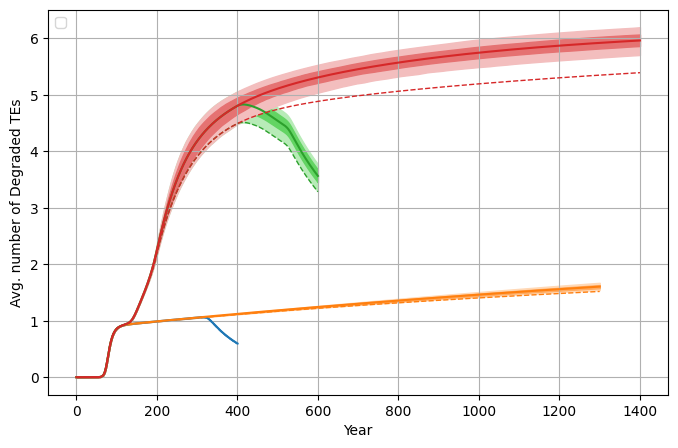

In [38]:
fig,ax = plt.subplots(figsize=(8,5))
theme_col = 'k'

# ax.plot(years[:D_hist.shape[-1]],D_hist.mean(axis=1).sum(axis=0),
#         color=util.lighten_color(theme_col,1),label='Mean')
# ax.fill_between(years[:D_hist.shape[-1]], 
#                  np.quantile(D_hist.sum(axis=0),0.05,axis=0),
#                  np.quantile(D_hist.sum(axis=0),0.95,axis=0),
#                  color=util.lighten_color(theme_col,0.3),
#                  edgecolor=util.lighten_color(theme_col,0.3),
#                  alpha=1,label='$(P_5,P_{95})$')
# ax.fill_between(years[:D_hist.shape[-1]], 
#                  np.quantile(D_hist.sum(axis=0),0.25,axis=0),
#                  np.quantile(D_hist.sum(axis=0),0.75,axis=0),
#                  color=util.lighten_color(theme_col,0.65),
#                  edgecolor=util.lighten_color(theme_col,0.65),
#                  alpha=1,label='$(P_{25},P_{75})$')
# ax.plot(years[:D_hist.shape[-1]],D_nointH.sum(axis=0),
#                              c=util.lighten_color(theme_col,1), 
#                              ls='--',lw=1,label='Sans interactions')

# colors = sns.dark_palette("seagreen",6)[::-1]
colors = prop_cycle.by_key()['color']
for j,s in enumerate(scenarios):
    ax.plot(np.arange(len(temps[s])),D[s][:,:,:].sum(axis=1).mean(axis=0),
        color=util.lighten_color(colors[j],1),label=scen_labels[j][3:])
    ax.fill_between(np.arange(len(temps[s])), 
                 np.quantile(D[s][:,:,:].sum(axis=1),0.05,axis=0),
                 np.quantile(D[s][:,:,:].sum(axis=1),0.95,axis=0),
                 color=util.lighten_color(colors[j],0.3),
                 edgecolor=util.lighten_color(colors[j],0.3),
                 alpha=1)
    ax.fill_between(np.arange(len(temps[s])), 
                 np.quantile(D[s][:,:,:].sum(axis=1),0.25,axis=0),
                 np.quantile(D[s][:,:,:].sum(axis=1),0.75,axis=0),
                 color=util.lighten_color(colors[j],0.65),
                 edgecolor=util.lighten_color(colors[j],0.65),
                 alpha=1)
    ax.plot(np.arange(len(temps[s])),D_noint[s][:,:].sum(axis=0),
                             c=util.lighten_color(colors[j],1), 
                             ls='--',lw=1)
    # if j> 0:
    # ax.annotate(scen_labels[j],(2350,D[j,:,:,:].sum(axis=1).mean(axis=0)[-1]),
    #             ha='left',va='center',fontsize=10,
    #             bbox=dict(fc='white',edgecolor='white',boxstyle='round'))

# ax.annotate(scen_labels[0],(2102,D_ssps[0,:,:,:].mean(axis=1).sum(axis=0)[-1]),
#             ha='left',va='top',fontsize=10,
#             bbox=dict(fc='white',edgecolor='white',boxstyle='round'))
# # ax.plot([1950,2125],[0.05*9]*2)
# ax.set_xlim([1950,2122])
# ax.annotate('Historical',(1982,0.1),ha='center',va='bottom',fontsize=10,
#                 bbox=dict(fc='none',edgecolor='none',boxstyle='round'))
# ax.set_ylim([0.5,3])

ax.grid()
ax.set_ylabel('Avg. number of Degraded TEs')
ax.set_xlabel('Year')

# cmap = mc.LinearSegmentedColormap.from_list('insert_name', [util.lighten_color(c,1) for c in colors], N=5)
# fig.colorbar(matplotlib.cm.ScalarMappable(cmap=cmap),ax=ax)

# ax.set_yscale('log')
legend=plt.legend(loc='upper left')